Dataset shape: (284807, 31)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Confusion Matrix:
[[204   0]
 [ 18  77]]

Precision: 1.0
Recall: 0.8105
F1-Score: 0.8953


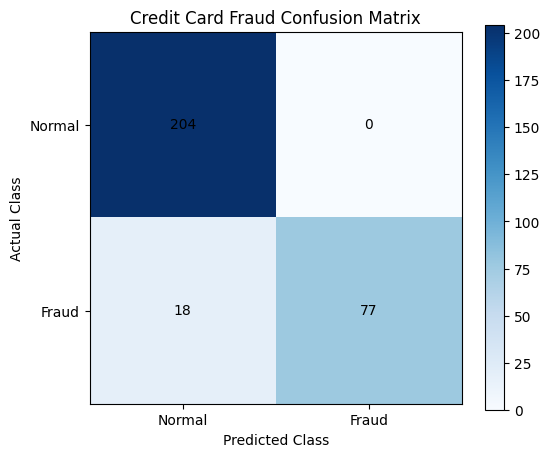

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load dataset directly from URL
url = "https://huggingface.co/datasets/David-Egea/Creditcard-fraud-detection/resolve/main/creditcard.csv"
df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Class"].value_counts())

# Create balanced subset: 1000 normal + 492 fraud transactions
normal = df[df["Class"] == 0].sample(n=1000, random_state=42)
fraud = df[df["Class"] == 1].sample(n=492, random_state=42)

data = pd.concat([normal, fraud], ignore_index=True)
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

# Separate predictors and target
X = data.drop(columns=["Class"]).to_numpy(dtype=float)
y = data["Class"].to_numpy(dtype=int)

# 2. Split into training (80%) and testing (20%)
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X[train_idx]
X_test = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

# Standardize using training-set statistics only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Add bias/intercept column
X_train = np.column_stack((np.ones(len(X_train)), X_train))
X_test = np.column_stack((np.ones(len(X_test)), X_test))

# 3. Define sigmoid function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Initialize weights
weights = np.zeros(X_train.shape[1])

# Train logistic regression using gradient descent
learning_rate = 0.01
epochs = 1000

for epoch in range(epochs):
    probabilities = sigmoid(X_train @ weights)
    gradient = X_train.T @ (probabilities - y_train) / len(y_train)
    weights -= learning_rate * gradient

# Predict probabilities and classes
y_prob = sigmoid(X_test @ weights)
y_pred = (y_prob >= 0.5).astype(int)

# 4. Compute confusion matrix values
TP = np.sum((y_test == 1) & (y_pred == 1))
TN = np.sum((y_test == 0) & (y_pred == 0))
FP = np.sum((y_test == 0) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == 0))

cm = np.array([[TN, FP],
               [FN, TP]])

print("\nConfusion Matrix:")
print(cm)

# Calculate Precision, Recall and F1-Score
precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0
f1 = (2 * precision * recall / (precision + recall)
      if precision + recall else 0)

print("\nPrecision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

# 5. Plot confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Credit Card Fraud Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.yticks([0, 1], ["Normal", "Fraud"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center")

plt.colorbar()
plt.show()
